### Group Information

**Course:** TTTC3213  
**Industry Domain:** Finance / FinTech  
**Dataset:** German Credit Data
| Name | Matric Number |
|---|---|
| Muhammad Aiman bin Ahmad Aswadi | A212178 |
| Haziq Syakir Bin Saipul Zahri  | A211783 |
| Mirza bin Ahmad Hafiz | A214180 |
| Adam Harris Bin Mohd Rezal | A212238 |

### Instructions to Run

1. Open the notebook in Google Colab.
2. Ensure an internet connection is available.
3. Click Runtime > Run all.
4. The dataset will be downloaded automatically, and all results will be displayed.

# Assignment 1: Data Profiling (EDA) Report

**Dataset:** German Credit Data  
**Domain:** Finance / FinTech

## 1. Scenario

A bank’s data engineering team wants to assess the quality of a historical credit dataset before using it for exploratory credit-risk analysis. Although the dataset contains no null cells, some categories combine unknown information with the absence of savings or property, several numerical values are statistically unusual, and demographic groups are unevenly represented. The profiling addresses three questions: how much information is ambiguous, which unusual values should be retained or investigated, and what limitations affect comparisons between demographic groups?

## 2. Data Source

The dataset used in this assignment is the Statlog (German Credit Data) dataset from the UCI Machine Learning Repository.

**Source:** [German Credit Dataset](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data)

The dataset was downloaded from the UCI website as a ZIP file and extracted in Google Colab. The `german.data` file was then loaded using Pandas.

The dataset contains 1,000 records and 21 columns, including customer credit information such as age, credit amount, loan duration, employment status, and credit risk.

In [ ]:
from IPython.display import display
from pathlib import Path
import urllib.request
import zipfile

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path.cwd() / "data" / "german_credit"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset folder:", DATA_DIR.resolve())

Dataset folder: /content/data/german_credit


In [ ]:
url = (
    "https://archive.ics.uci.edu/static/public/144/"
    "statlog+german+credit+data.zip"
)

zip_path = DATA_DIR / "german_credit.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(DATA_DIR)

print("Available dataset files:")
print(sorted(path.name for path in DATA_DIR.iterdir()))

Available dataset files:
['Index', 'german.data', 'german.data-numeric', 'german.doc', 'german_credit.zip']


In [ ]:
# Column names for German Credit Data
columns = [
    'Status', 'Duration', 'CreditHistory', 'Purpose',
    'CreditAmount', 'Savings', 'Employment',
    'InstallmentRate', 'PersonalStatus', 'OtherDebtors',
    'ResidenceSince', 'Property', 'Age',
    'OtherInstallmentPlans', 'Housing',
    'ExistingCredits', 'Job', 'PeopleLiable',
    'Telephone', 'ForeignWorker', 'CreditRisk'
]

# Load dataset

# Load German Credit dataset
df = pd.read_csv(
    DATA_DIR / "german.data",
    sep=r"\s+",
    header=None,
    names=columns,
)

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check dataset information
df.info()

First 5 Rows:


,Status,Duration,CreditHistory,Purpose,CreditAmount,Savings,Employment,InstallmentRate,PersonalStatus,OtherDebtors,...,Property,Age,OtherInstallmentPlans,Housing,ExistingCredits,Job,PeopleLiable,Telephone,ForeignWorker,CreditRisk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


Dataset Shape: (1000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Status                 1000 non-null   object
 1   Duration               1000 non-null   int64 
 2   CreditHistory          1000 non-null   object
 3   Purpose                1000 non-null   object
 4   CreditAmount           1000 non-null   int64 
 5   Savings                1000 non-null   object
 6   Employment             1000 non-null   object
 7   InstallmentRate        1000 non-null   int64 
 8   PersonalStatus         1000 non-null   object
 9   OtherDebtors           1000 non-null   object
 10  ResidenceSince         1000 non-null   int64 
 11  Property               1000 non-null   object
 12  Age                    1000 non-null   int64 
 13  OtherInstallmentPlans  1000 non-null   object
 14  Housing                1000 non-null   object
 

## 3. Data Profiling and Issue Handling

This section checks missing values, outliers, duplicates, invalid values, and categorical values to identify potential data quality problems.

In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Create missing values summary table
missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage (%)': missing_percentage
})

print("Missing Values Summary:")
display(missing_summary)

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())


Missing Values Summary:


,Missing Count,Missing Percentage (%)
Status,0,0.0
Duration,0,0.0
CreditHistory,0,0.0
Purpose,0,0.0
CreditAmount,0,0.0
Savings,0,0.0
Employment,0,0.0
InstallmentRate,0,0.0
PersonalStatus,0,0.0
OtherDebtors,0,0.0


Total Missing Values: 0


### Missing Values Handling

The null-value check found zero missing cells across all 21 columns. Therefore, no rows or columns were dropped, and no imputation was performed for null values.

However, Savings=A65 combines “unknown” with “no savings account” and occurs in 183 records (18.3%). Property=A124 combines “unknown” with “no property” and occurs in 154 records (15.4%). These counts apply separately and may involve overlapping records.

I retained these codes because the available data cannot distinguish unknown information from confirmed absence. Treating every occurrence as missing or imputing a financial category would introduce unsupported assumptions. Consequently, zero null cells does not establish complete knowledge of customers’ savings or property.

In [ ]:
# Detect outliers using IQR method

numerical_cols = ['Age', 'CreditAmount', 'Duration']

outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage (%)': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

print("Outlier Detection Summary:")
display(outlier_df)


Outlier Detection Summary:


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%)
0,Age,4.500,64.500,23,2.3
1,CreditAmount,-2544.625,7882.375,72,7.2
2,Duration,-6.000,42.000,70,7.0


In [ ]:
# Keep the existing IQR detection cell before this cell.
numerical_cols = ["Age", "CreditAmount", "Duration"]

# Preserve row-level evidence of statistical outliers.
outlier_flags = pd.DataFrame(index=df.index)

for col in numerical_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outlier_flags[f"{col}_IQR_flag"] = (
        (df[col] < q1 - 1.5 * iqr)
        | (df[col] > q3 + 1.5 * iqr)
    )

# Retain original records and values; add three audit columns.
df_cleaned = df.copy().join(outlier_flags)
any_outlier = outlier_flags.any(axis=1)

print("Observed numerical ranges:")
display(df[numerical_cols].agg(["min", "max"]).T)

print("Outlier counts by feature:")
display(outlier_flags.sum().to_frame("Flagged Records"))

print("Distinct records with at least one flag:", int(any_outlier.sum()))
print("Rows retained:", len(df_cleaned))

print("Example flagged records (original row indices preserved):")
display(
    df_cleaned.loc[
        any_outlier,
        numerical_cols + list(outlier_flags.columns)
    ].head(10)
)

Observed numerical ranges:


,min,max
Age,19,75
CreditAmount,250,18424
Duration,4,72


Outlier counts by feature:


,Flagged Records
Age_IQR_flag,23
CreditAmount_IQR_flag,72
Duration_IQR_flag,70


Distinct records with at least one flag: 138
Rows retained: 1000
Example flagged records (original row indices preserved):


,Age,CreditAmount,Duration,Age_IQR_flag,CreditAmount_IQR_flag,Duration_IQR_flag
0,67,1169,6,True,False,False
1,22,5951,48,False,False,True
5,35,9055,36,False,True,False
11,24,4308,48,False,False,True
17,25,8072,30,False,True,False
18,44,12579,24,False,True,False
29,63,6836,60,False,False,True
35,25,4746,45,False,False,True
36,31,6110,48,False,False,True
44,58,6143,48,False,False,True


### Outlier Handling

Outliers were identified using the 1.5×IQR rule for Age, CreditAmount, and Duration. This flagged 23 age values, 72 credit amounts, and 70 loan durations. Because some records were flagged for multiple features, 138 distinct records had at least one flag.

The observed ranges were 19–75 years for age, 250–18,424 for credit amount, and 4–72 months for duration. Older applicants, larger loans, and longer repayment periods are plausible in a lending dataset. However, plausibility does not confirm accuracy, and the original customer records are unavailable for verification.

I therefore retained all original values and added a separate Boolean flag for each feature. Removing these records could exclude legitimate applicants, while capping them would replace observed values with unsupported thresholds. The flags preserve the uncertainty for further review.

All 1,000 records were retained. The resulting dataset contains the original 21 columns plus three outlier-flag columns. These flags identify statistical extremes; the accuracy of the flagged values remains a limitation.

In [ ]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Display duplicate records if found
if duplicate_count > 0:
    print("\nDuplicate Records:")
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate records found.")


Total Duplicate Records: 0
No duplicate records found.


In [ ]:
# Check invalid numerical values
print("Invalid Values Check")

print("Age <= 0:", (df['Age'] <= 0).sum())
print("CreditAmount <= 0:", (df['CreditAmount'] <= 0).sum())
print("Duration <= 0:", (df['Duration'] <= 0).sum())

# Check invalid credit risk categories
invalid_risk = ~df['CreditRisk'].isin([1, 2])
print("Invalid CreditRisk:", invalid_risk.sum())

# Display minimum and maximum values
print("\nNumerical Summary:")
display(df[['Age', 'CreditAmount', 'Duration']].describe())


Invalid Values Check
Age <= 0: 0
CreditAmount <= 0: 0
Duration <= 0: 0
Invalid CreditRisk: 0

Numerical Summary:


,Age,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000
mean,35.546000,3271.258000,20.903000
std,11.375469,2822.736876,12.058814
min,19.000000,250.000000,4.000000
25%,27.000000,1365.500000,12.000000
50%,33.000000,2319.500000,18.000000
75%,42.000000,3972.250000,24.000000
max,75.000000,18424.000000,72.000000


In [ ]:
count_columns = ["ExistingCredits", "PeopleLiable"]
validation_results = []

for col in count_columns:
    values = pd.to_numeric(df[col], errors="coerce")

    valid = (
        values.notna()
        & values.ge(0)
        & values.mod(1).eq(0)
    )
    invalid = ~valid

    validation_results.append({
        "Column": col,
        "Rule": "Nonnegative whole number",
        "Invalid Count": int(invalid.sum()),
        "Invalid Percentage (%)": round(invalid.mean() * 100, 2),
    })

    if invalid.any():
        print(f"Records requiring investigation: {col}")
        display(df.loc[invalid, [col]])

count_validation = pd.DataFrame(validation_results)
display(count_validation)

,Column,Rule,Invalid Count,Invalid Percentage (%)
0,ExistingCredits,Nonnegative whole number,0,0.0
1,PeopleLiable,Nonnegative whole number,0,0.0


In [ ]:
# Validate categorical values using German Credit dataset codes

valid_categories = {
    'Status': ['A11', 'A12', 'A13', 'A14'],
    'CreditHistory': ['A30', 'A31', 'A32', 'A33', 'A34'],
    'Purpose': ['A40', 'A41', 'A42', 'A43', 'A44',
                'A45', 'A46', 'A47', 'A48', 'A49', 'A410'],
    'Savings': ['A61', 'A62', 'A63', 'A64', 'A65'],
    'Employment': ['A71', 'A72', 'A73', 'A74', 'A75'],
    'PersonalStatus': ['A91', 'A92', 'A93', 'A94', 'A95'],
    'OtherDebtors': ['A101', 'A102', 'A103'],
    'Property': ['A121', 'A122', 'A123', 'A124'],
    'OtherInstallmentPlans': ['A141', 'A142', 'A143'],
    'Housing': ['A151', 'A152', 'A153'],
    'Job': ['A171', 'A172', 'A173', 'A174'],
    'Telephone': ['A191', 'A192'],
    'ForeignWorker': ['A201', 'A202']
}

# Check invalid category codes
for col, valid_values in valid_categories.items():
    invalid = df[~df[col].isin(valid_values)]
    print(f"{col}: {len(invalid)} invalid values")

# Check data types
print("\nDataset Data Types:")
display(df.dtypes.to_frame(name='Data Type'))


Status: 0 invalid values
CreditHistory: 0 invalid values
Purpose: 0 invalid values
Savings: 0 invalid values
Employment: 0 invalid values
PersonalStatus: 0 invalid values
OtherDebtors: 0 invalid values
Property: 0 invalid values
OtherInstallmentPlans: 0 invalid values
Housing: 0 invalid values
Job: 0 invalid values
Telephone: 0 invalid values
ForeignWorker: 0 invalid values

Dataset Data Types:


,Data Type
Status,object
Duration,int64
CreditHistory,object
Purpose,object
CreditAmount,int64
Savings,object
Employment,object
InstallmentRate,int64
PersonalStatus,object
OtherDebtors,object


### Other Data Quality Issues Handling

Exact-row duplicate checking found zero duplicate records. The numerical checks found no nonpositive Age, CreditAmount, or Duration values. ExistingCredits and PeopleLiable contained no values violating the basic nonnegative whole-number rule. CreditRisk contained only the expected target codes, 1 and 2.

The 13 categorical predictors were checked against the documented code lists, with no unexpected codes found. The displayed data types showed integer representations for numerical fields and text representations for categorical codes. No conversion or correction was required for these checks.

These results establish compliance with the specific rules tested; they do not establish the accuracy of every value or complete coverage of all domain constraints. In particular, detailed source-supported domain validation for InstallmentRate and ResidenceSince remains incomplete.

All 21 original columns and their values were preserved. The resulting dataset additionally contains three Boolean outlier-flag columns, giving 24 columns in total.

In [ ]:
invalid_category_count = sum(
    int((~df[col].isin(allowed)).sum())
    for col, allowed in valid_categories.items()
)

quality_log = pd.DataFrame(
    [
        (
            "Null values",
            int(df.isna().sum().sum()),
            "cells",
            "No null treatment required",
        ),
        (
            "Ambiguous Savings code A65",
            int(df["Savings"].eq("A65").sum()),
            "records",
            "Retain code; document unknown/absence ambiguity",
        ),
        (
            "Ambiguous Property code A124",
            int(df["Property"].eq("A124").sum()),
            "records",
            "Retain code; document unknown/absence ambiguity",
        ),
        (
            "Exact duplicate rows",
            int(df.duplicated().sum()),
            "records",
            "No deduplication required",
        ),
        (
            "Invalid documented categorical codes",
            invalid_category_count,
            "cells",
            "No categorical corrections required",
        ),
        (
            "At least one IQR outlier flag",
            int(outlier_flags.any(axis=1).sum()),
            "records",
            "Retain original values; add three Boolean flags",
        ),
    ],
    columns=["Check", "Affected Count", "Count Unit", "Handling Decision"],
)

display(quality_log)

print("Original rows:", len(df))
print("Resulting rows:", len(df_cleaned))
print(
    "Original columns and values preserved:",
    df_cleaned[df.columns].equals(df),
)

,Check,Affected Count,Count Unit,Handling Decision
0,Null values,0,cells,No null treatment required
1,Ambiguous Savings code A65,183,records,Retain code; document unknown/absence ambiguity
2,Ambiguous Property code A124,154,records,Retain code; document unknown/absence ambiguity
3,Exact duplicate rows,0,records,No deduplication required
4,Invalid documented categorical codes,0,cells,No categorical corrections required
5,At least one IQR outlier flag,138,records,Retain original values; add three Boolean flags


Original rows: 1000
Resulting rows: 1000
Original columns and values preserved: True


The handling log links the main profiling findings to their treatment decisions. Counts should not be added together because checks use different units and may involve overlapping records.

No null-value treatment, deduplication, or categorical correction was performed because those checks found no violations. Ambiguous categories were preserved because their underlying meanings cannot be separated reliably. Statistically unusual numerical values were retained with three additional outlier flags because they were not established as errors.

The resulting dataset is therefore profiled and flagged, with all original records and values preserved. This demonstrates documented handling decisions, but it does not demonstrate correction of confirmed source errors. The separate numerical-validation tables provide evidence for the numerical rules checked.

## 4. Exploratory (Diagnostic) Charts

The following charts are used to identify potential data quality issues, including outliers and class imbalance in the German Credit Dataset.

*   Boxplot
*   BarChart



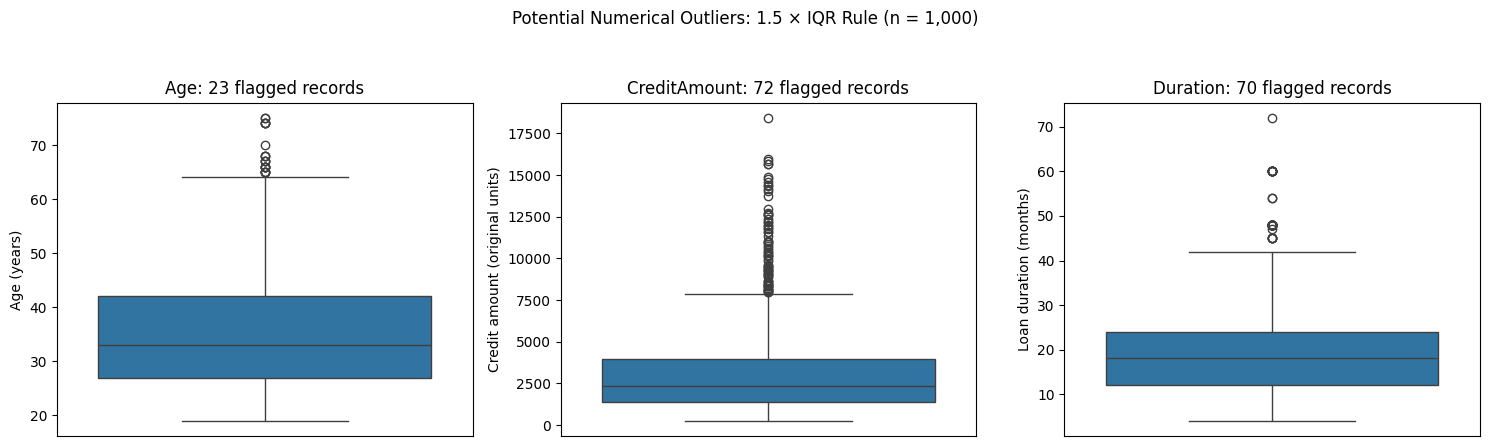

In [ ]:
features = ["Age", "CreditAmount", "Duration"]

axis_labels = {
    "Age": "Age (years)",
    "CreditAmount": "Credit amount (original units)",
    "Duration": "Loan duration (months)",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, features):
    sns.boxplot(data=df, y=col, whis=1.5, ax=ax)

    flag_count = int(outlier_flags[f"{col}_IQR_flag"].sum())

    ax.set_title(f"{col}: {flag_count} flagged records")
    ax.set_ylabel(axis_labels[col])
    ax.set_xlabel("")
    ax.set_xticks([])

fig.suptitle(
    f"Potential Numerical Outliers: 1.5 × IQR Rule (n = {len(df):,})"
)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

,Record Count,Percentage (%)
CreditRisk,,
1,700,70.0
2,300,30.0


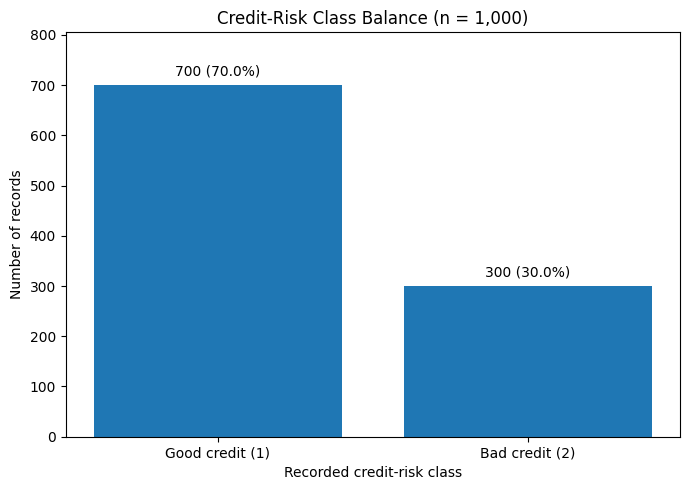

In [ ]:
risk_counts = (
    df["CreditRisk"]
    .value_counts()
    .reindex([1, 2], fill_value=0)
)

risk_percentage = risk_counts / len(df) * 100

risk_summary = pd.DataFrame({
    "Record Count": risk_counts,
    "Percentage (%)": risk_percentage.round(1),
})
display(risk_summary)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Good credit (1)", "Bad credit (2)"],
    risk_counts.to_numpy()
)

for bar, count, percentage in zip(
    bars, risk_counts, risk_percentage
):
    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

ax.set_title(f"Credit-Risk Class Balance (n = {len(df):,})")
ax.set_xlabel("Recorded credit-risk class")
ax.set_ylabel("Number of records")
ax.set_ylim(0, risk_counts.max() * 1.15)

fig.tight_layout()
plt.show()

### Credit Risk Class Distribution

The dataset contains 700 good-credit records (70%) and 300 bad-credit records (30%), demonstrating an unequal target-class distribution. These are record counts; the absence of a customer identifier prevents verification of unique customer counts.

The original distribution was retained because class imbalance alone does not establish a data error. Resampling would change the observed distribution and is unnecessary for this profiling task. Any future predictive evaluation should account for the unequal class frequencies.

## 5. PII and Bias Risks

This section identifies potential privacy and bias risks in the German Credit Dataset, including sensitive customer attributes and imbalanced credit risk groups.

In [ ]:
# Labels follow the published UCI codebook.
foreign_worker_labels = {
    "A201": "Foreign worker: Yes",
    "A202": "Foreign worker: No",
}

counts = df["ForeignWorker"].value_counts(dropna=False)

foreign_worker_summary = pd.DataFrame({
    "Source Code": counts.index,
    "Meaning": [
        foreign_worker_labels.get(code, "Unrecognised code")
        for code in counts.index
    ],
    "Record Count": counts.to_numpy(),
    "Percentage (%)": (counts.to_numpy() / len(df) * 100).round(2),
})

display(foreign_worker_summary)

,Source Code,Meaning,Record Count,Percentage (%)
0,A201,Foreign worker: Yes,963,96.3
1,A202,Foreign worker: No,37,3.7


### PII and Bias Risks

The dataset contains no direct customer identifiers such as names, addresses, or actual telephone numbers. Telephone indicates whether a telephone is registered under the customer’s name; it does not contain the number itself.

However, Age may contribute to identification when combined with other information, CreditAmount contains financial information, and ForeignWorker describes a potentially sensitive demographic characteristic. PersonalStatus combines sex and marital status, so it should not be interpreted as a standalone marital-status variable.

For non-public banking data, original customer records should be accessible only to authorised users. Shared diagnostic reports should use aggregate results, consider age bands when exact ages are unnecessary, and avoid detailed breakdowns of very small groups. These measures reduce exposure but do not guarantee anonymity. Sensitive attributes may still be needed under controlled access for fairness auditing; removing them alone would not establish fairness.

Following the published UCI coding, ForeignWorker contains 963 records coded “Yes” (96.3%) and 37 coded “No” (3.7%). This shows substantial demographic imbalance within the dataset.

The smaller group provides limited evidence for group comparisons. However, unequal representation alone does not establish discrimination or sampling bias: the sampling process and the demographic composition of the intended banking population would also need examination.

I retained both groups and their original frequencies. Removing records or automatically balancing the groups would alter the observed sample without evidence of the appropriate population distribution. Group comparisons should report their sample sizes and acknowledge uncertainty for the smaller group. Before applying findings to another banking population, its demographic coverage should be assessed against that population.

## 6. Conclusion

The German Credit Dataset is suitable for educational data profiling and cautious exploratory credit-risk analysis. However, the checks performed do not establish its suitability for operational lending decisions.

Profiling found 1,000 records, zero null cells, and zero exact duplicate rows. The checked category codes and numerical validity rules produced no violations. Nevertheless, Savings and Property contain categories that combine unknown information with confirmed absence, limiting how confidently these fields can be interpreted.

The IQR method identified 138 distinct records with at least one unusual numerical value. All original records and values were retained, and three Boolean outlier flags were added to support further investigation. No original values were corrected because the checks did not establish that they were erroneous.

The remaining limitations are:

- Unknown information cannot be separated from confirmed absence in the combined Savings and Property categories.
- Flagged extreme values are plausible but have not been verified against original customer records.
- Numerical validation covers selected basic rules and does not establish the accuracy of every value.
- Exact-row duplicate checking cannot establish whether the same customer appears more than once because no customer identifier is available.
- The smaller ForeignWorker group contains only 37 records, limiting demographic comparisons.
- The historical dataset’s sampling process and applicability to a current banking population remain uncertain.

Before operational use, further work would be required to verify source accuracy, complete source-supported validation rules, assess population coverage, and investigate potential demographic disparities.